# Notebook 02 — CT Preprocessing (Brain Tumor CT Dataset)
Loads CT brain tumor images from Kaggle dataset, labels by folder name, visualizes distribution, and saves 70/15/15 splits.

> **Dataset:** Head CT Images for Classification (nipaanjum/head-ct-images-for-classification)
> - `yes/` folder → Tumor (label 1) — 100 images
> - `no/` folder → Healthy (label 0) — 100 images

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


## 2. Download CT Dataset from Kaggle

In [2]:
import os

# Upload your kaggle.json API key
from google.colab import files
files.upload()  # select kaggle.json

os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
os.system("cp kaggle.json ~/.kaggle/")
os.system("chmod 600 ~/.kaggle/kaggle.json")
print("Kaggle API ready!")

Saving kaggle.json to kaggle.json
Kaggle API ready!


In [3]:
ct_extract = "/content/ct_tumor/"
check_file = "/content/ct_tumor/dataset/head ct/no"

if not os.path.exists(check_file):
    print("Downloading CT dataset...")
    os.makedirs(ct_extract, exist_ok=True)
    os.system(f"kaggle datasets download -d nipaanjum/head-ct-images-for-classification -p {ct_extract}")
    os.system(f"unzip {ct_extract}/*.zip -d {ct_extract}")
    print("Done!")
else:
    print("Already downloaded, skipping.")

Done!


## 3. Imports

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

## 4. Load and Label Images

In [5]:
ct_path = Path("/content/ct_tumor/dataset/head ct")

ct_files  = []
ct_labels = []

for img_path in list(ct_path.rglob("*.png")) + list(ct_path.rglob("*.jpg")) + list(ct_path.rglob("*.jpeg")):
    folder_name = img_path.parent.name.lower()
    if folder_name == "yes":
        ct_files.append(img_path)
        ct_labels.append(1)   # Tumor
    elif folder_name == "no":
        ct_files.append(img_path)
        ct_labels.append(0)   # Healthy

print(f"Total CT images: {len(ct_files)}")
print(f"Tumor (yes): {ct_labels.count(1)}")
print(f"Healthy (no): {ct_labels.count(0)}")

Total CT images: 200
Tumor (yes): 100
Healthy (no): 100


## 5. Class Distribution

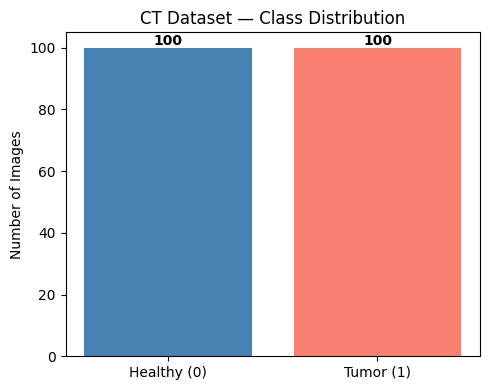

Healthy: 100 | Tumor: 100


In [6]:
counts = np.bincount(ct_labels)
plt.figure(figsize=(5, 4))
plt.bar(["Healthy (0)", "Tumor (1)"], counts, color=["steelblue", "salmon"])
plt.title("CT Dataset — Class Distribution")
plt.ylabel("Number of Images")
for i, v in enumerate(counts):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()
print(f"Healthy: {counts[0]} | Tumor: {counts[1]}")

## 6. Visualize Sample (Raw vs Processed)

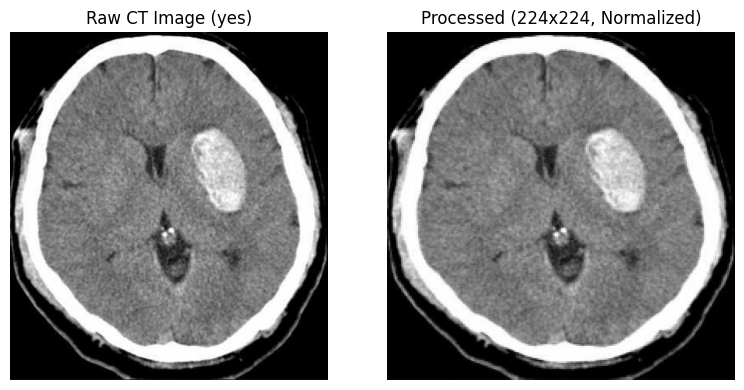

Label: 1 (Tumor)


In [7]:
sample_path = ct_files[0]
img_raw  = cv2.cvtColor(cv2.imread(str(sample_path)), cv2.COLOR_BGR2RGB)
img_gray = cv2.imread(str(sample_path), cv2.IMREAD_GRAYSCALE)
img_norm = cv2.resize(img_gray, (224, 224)) / 255.0

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_raw)
plt.title(f"Raw CT Image ({sample_path.parent.name})")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(img_norm, cmap="gray")
plt.title("Processed (224x224, Normalized)")
plt.axis("off")
plt.tight_layout()
plt.show()
print(f"Label: {ct_labels[0]} ({'Tumor' if ct_labels[0]==1 else 'Healthy'})")

## 7. Train / Validation / Test Split (70 / 15 / 15)

In [8]:
ct_files_arr  = np.array(ct_files,  dtype=object)
ct_labels_arr = np.array(ct_labels)

train_paths, temp_paths, y_train, y_temp = train_test_split(
    ct_files_arr, ct_labels_arr,
    test_size=0.40, random_state=42, stratify=ct_labels_arr
)
val_paths, test_paths, y_val, y_test = train_test_split(
    temp_paths, y_temp,
    test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train:      {len(train_paths)} images | {np.bincount(y_train)}")
print(f"Validation: {len(val_paths)}  images | {np.bincount(y_val)}")
print(f"Test:       {len(test_paths)}  images | {np.bincount(y_test)}")

Train:      120 images | [60 60]
Validation: 40  images | [20 20]
Test:       40  images | [20 20]


## 8. Save Splits to Google Drive

In [9]:
os.makedirs("/content/drive/MyDrive/CT_Tumor", exist_ok=True)

np.savez(
    "/content/drive/MyDrive/CT_Tumor/ct_splits.npz",
    train_paths=train_paths.astype(str),
    val_paths=val_paths.astype(str),
    test_paths=test_paths.astype(str),
    y_train=y_train, y_val=y_val, y_test=y_test
)
print("Saved ct_splits.npz to Google Drive.")
print("Load with: data = np.load('/content/drive/MyDrive/CT_Tumor/ct_splits.npz', allow_pickle=True)")

Saved ct_splits.npz to Google Drive.
Load with: data = np.load('/content/drive/MyDrive/CT_Tumor/ct_splits.npz', allow_pickle=True)
